In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [2]:
diabetes = load_diabetes()

In [3]:
df = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)

df["Target"] = diabetes.target

print(df.head())

        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  Target  
0 -0.002592  0.019907 -0.017646   151.0  
1 -0.039493 -0.068332 -0.092204    75.0  
2 -0.002592  0.002861 -0.025930   141.0  
3  0.034309  0.022688 -0.009362   206.0  
4 -0.002592 -0.031988 -0.046641   135.0  


In [4]:
X = df.drop("Target", axis=1)

y = df["Target"]

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [6]:
model = LinearRegression()

In [7]:
model.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [8]:
y_pred = model.predict(X_test)

In [9]:
result = pd.DataFrame({
    "Actual Value": y_test.values,
    "Predicted Value": y_pred
})

print(result.head(10))

   Actual Value  Predicted Value
0         219.0       139.547558
1          70.0       179.517208
2         202.0       134.038756
3         230.0       291.417029
4         111.0       123.789659
5          84.0        92.172347
6         242.0       258.232389
7         272.0       181.337321
8          94.0        90.224113
9          96.0       108.633759


In [10]:
mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("Mean Squared Error =", mse)

print("Root Mean Squared Error =", rmse)

print("R2 Score =", r2)

Mean Squared Error = 2900.1936284934814
Root Mean Squared Error = 53.85344583676593
R2 Score = 0.4526027629719195


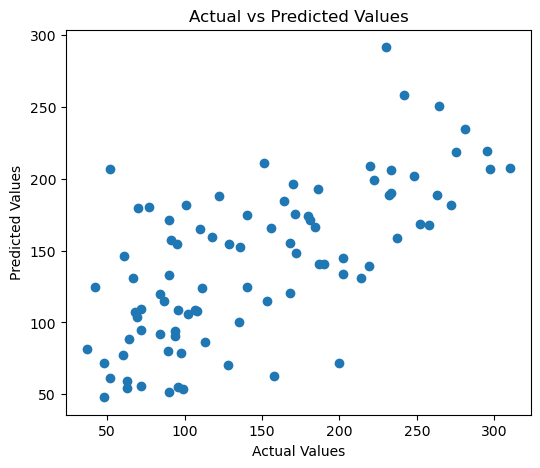

In [11]:
plt.figure(figsize=(6, 5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Values")

plt.ylabel("Predicted Values")

plt.title("Actual vs Predicted Values")

plt.show()

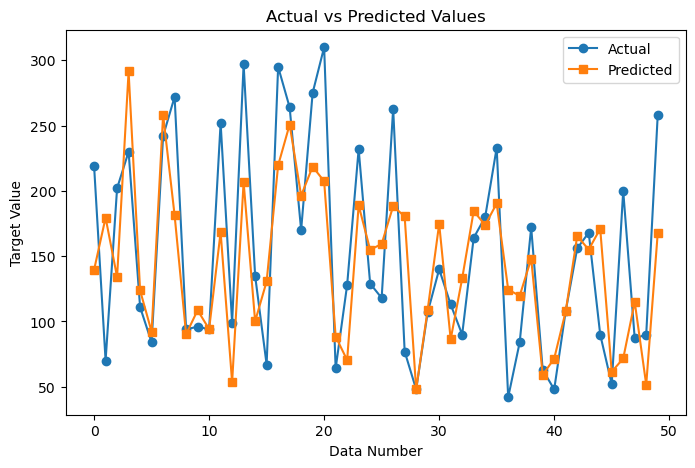

In [12]:
plt.figure(figsize=(8, 5))

plt.plot(y_test.values[:50], label="Actual", marker="o")

plt.plot(y_pred[:50], label="Predicted", marker="s")

plt.xlabel("Data Number")

plt.ylabel("Target Value")

plt.title("Actual vs Predicted Values")

plt.legend()

plt.show()